# 01 · Corpus científico: limpieza y Análisis Exploratorio (EDA)
**Proyecto integrador – Detección de cojera equina** · Carlos Barrera

Fase CRISP-DM: *Comprensión de los datos* y *Preparación de los datos*.

Fuente: API REST de OpenAlex (`src/scraping/openalex_scraper.py`), 5 consultas temáticas
(cojera equina, marcha equina, sensores inerciales, visión/pose animal y cojera con ML en otras especies).
Cada consulta trae los ~1.500 registros más relevantes.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "openalex_works_raw.csv"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figuras" / "01_articulos_eda"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
ANIO_CORTE = 2026  # año de la extracción

raw = pd.read_csv(RAW)
print("Dimensión cruda:", raw.shape)
raw.head(3)

Dimensión cruda: (6472, 26)


,openalex_id,doi,titulo,anio,fecha,tipo,idioma,citas,fwci,retractado,...,n_paises,instituciones,n_referencias,keywords,conceptos,topico,subcampo,campo,resumen,consulta
0,https://openalex.org/W1507175280,NaN,Adams' Lameness in Horses,1987.0,1987-01-01,book,en,223,18.0000,False,...,0,NaN,0,equine lameness;horses;lameness diagnosis;lame...,Lameness;Medicine;Physical examination;Radiogr...,Veterinary Equine Medical Research,Equine,Veterinary,This fifth edition represents a detailed revie...,cojera_equina
1,https://openalex.org/W1509575544,https://doi.org/10.1016/c2009-0-50774-x,Diagnosis and Management of Lameness in the Horse,2011.0,2011-01-01,book,en,744,81.6406,False,...,0,NaN,0,lameness;horses;equine lameness diagnosis;vete...,Lameness;Horse,Veterinary Equine Medical Research,Equine,Veterinary,NaN,cojera_equina
2,https://openalex.org/W4301434042,https://doi.org/10.1016/b978-0-7216-8342-3.x50...,Diagnosis and Management of Lameness in the Horse,2003.0,2003-01-01,book,en,461,20.5313,False,...,0,NaN,0,lameness;horses;equine lameness diagnosis;vete...,Lameness;Horse,Veterinary Equine Medical Research,Equine,Veterinary,NaN,cojera_equina


## 1. Diagnóstico de calidad de los datos crudos

In [2]:
diag = pd.DataFrame({
    "nulos_%": (raw.isna().mean() * 100).round(1),
    "tipo": raw.dtypes.astype(str),
    "valores_unicos": raw.nunique(),
}).sort_values("nulos_%", ascending=False)
print("Registros duplicados por ID (mismo artículo en varias consultas):",
      raw.duplicated("openalex_id").sum())
diag

Registros duplicados por ID (mismo artículo en varias consultas): 610


,nulos_%,tipo,valores_unicos
paises,30.2,str,492
instituciones,30.2,str,2526
resumen,27.3,str,4158
fwci,21.8,float64,2300
doi,13.3,str,5053
tipo_fuente,3.8,str,5
revista,3.8,str,1626
titulo,0.4,str,5496
conceptos,0.2,str,5463
fecha,0.1,str,2882


**Lectura:** el resumen falta en ~27 % de los registros (OpenAlex no puede redistribuir algunos
resúmenes por derechos de autor), y país/institución faltan en ~30 %. El FWCI (impacto normalizado por campo)
falta en ~22 %, sobre todo en trabajos muy recientes o muy antiguos. Hay ~600 duplicados porque un mismo artículo
puede responder a varias consultas: esa coincidencia es información útil (multi-temática), así que se conserva
como variable en vez de descartarla.

## 2. Limpieza y transformación
Decisiones (cada una justificada):
1. **Fusionar duplicados por ID** conservando la lista de consultas → variable `n_consultas` (interdisciplinariedad).
2. **Excluir tipos no científicos o redundantes**: `peer-review` (informes de revisión), `erratum`, `paratext`, `letter`, `editorial`.
3. **Excluir retractados** (1 registro): no son evidencia válida.
4. **Ventana temporal 1990–2026**: antes de 1990 casi no hay producción comparable y los años > 2026 son
   fechas de publicación anticipada (*online first*); se recortan para no distorsionar las tendencias.
5. **Duplicados por título normalizado** (preprint + versión publicada): se conserva el de más citas.
6. **Nulos**: país → `"Desconocido"`; resumen → se marca `tiene_resumen` y el texto para minería usa título + keywords;
   FWCI se deja como NaN (imputarlo inventaría impacto) y se usa solo en análisis con casos completos.
7. **Filtro de pertinencia**: se exige al menos un término del dominio (caballo, cojera, marcha, pose…), porque
   palabras como *markerless* también aparecen en genética y traen ruido.

In [3]:
df = raw.copy()
consultas = df.groupby("openalex_id")["consulta"].apply(lambda s: ";".join(sorted(set(s))))
df = df.drop_duplicates("openalex_id").drop(columns="consulta").merge(consultas, on="openalex_id")
df["n_consultas"] = df["consulta"].str.count(";") + 1
log = [("Registros únicos por ID", len(df))]

excluir_tipo = ["peer-review", "erratum", "paratext", "letter", "editorial", "other", "supplementary-materials"]
df = df[~df["tipo"].isin(excluir_tipo)]; log.append(("Tras excluir tipos no científicos", len(df)))
df = df[df["retractado"] != True]; log.append(("Tras excluir retractados", len(df)))
df = df[df["anio"].between(1990, ANIO_CORTE)]; log.append(("Ventana 1990–2026", len(df)))

df["titulo_norm"] = df["titulo"].fillna("").str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip()
df = df[df["titulo_norm"].str.len() > 10]
df = df.sort_values("citas", ascending=False).drop_duplicates("titulo_norm")
log.append(("Tras quitar duplicados por título", len(df)))

# 7. Filtro de pertinencia temática: la palabra "markerless" también se usa en genética
#    (mutantes sin marcador) y "keypoint" en otras áreas; se exige al menos un término del dominio.
_txt = (df["titulo"].fillna("") + " " + df["resumen"].fillna("") + " " + df["keywords"].fillna("")).str.lower()
DOMINIO = r"horse|equine|equid|pony|lame|gait|locomot|pose estimation|keypoint|posture|kinemat|limb|stride|animal behavio"
df = df[_txt.str.contains(DOMINIO, regex=True)]
# "kinematics" también trae estudios de cinemática espermática (semen de sementales): fuera de alcance.
# Este ruido se descubrió con las reglas de asociación del notebook 02 (regla sperm kinematics → sperm motility, lift ≈ 110).
df = df[~_txt.loc[df.index].str.contains(r"sperm|semen|spermat", regex=True)]
log.append(("Tras filtro de pertinencia temática", len(df)))

df["paises"] = df["paises"].fillna("Desconocido")
df["pais_principal"] = df["paises"].str.split(";").str[0]
df["tiene_resumen"] = df["resumen"].notna()
df["acceso_abierto"] = df["acceso_abierto"].fillna(False).astype(bool)
df["revista"] = df["revista"].fillna("Sin fuente registrada")
df["keywords"] = df["keywords"].fillna("")

pd.DataFrame(log, columns=["Paso", "Registros"])

,Paso,Registros
0,Registros únicos por ID,5862
1,Tras excluir tipos no científicos,5431
2,Tras excluir retractados,5430
3,Ventana 1990–2026,5166
4,Tras quitar duplicados por título,4995
5,Tras filtro de pertinencia temática,4024


## 3. Atributos derivados (ingeniería de variables)

In [4]:
df["edad"] = (ANIO_CORTE - df["anio"]).clip(lower=0) + 1
df["citas_por_anio"] = df["citas"] / df["edad"]
df["log_citas"] = np.log1p(df["citas"])
df["n_keywords"] = df["keywords"].apply(lambda s: len([k for k in s.split(";") if k]))
df["long_resumen"] = df["resumen"].fillna("").str.split().str.len()
df["texto"] = (df["titulo"].fillna("") + ". " + df["resumen"].fillna("") + " " + df["keywords"].str.replace(";", " "))

TEMAS = {
    "vision": r"computer vision|deep learning|convolutional|pose estimation|keypoint|markerless|video|image",
    "sensores": r"inertial|accelerom|gyroscop|\bimu\b|sensor",
    "ml": r"machine learning|random forest|support vector|neural network|classifier|classification",
    "clinico": r"diagnos|nerve block|analgesi|radiograph|ultrason|treatment|clinical",
}
for t, pat in TEMAS.items():
    df[f"tema_{t}"] = df["texto"].str.lower().str.contains(pat, regex=True)
df["periodo"] = pd.cut(df["anio"], [1989, 2005, 2015, 2020, ANIO_CORTE],
                       labels=["1990–2005", "2006–2015", "2016–2020", "2021–2026"])
print("Dataset limpio:", df.shape)
df[["titulo", "anio", "citas", "citas_por_anio", "n_consultas", "tema_vision", "tema_sensores"]].head()

Dataset limpio: (4024, 41)


,titulo,anio,citas,citas_por_anio,n_consultas,tema_vision,tema_sensores
3440,DeepLabCut: markerless pose estimation of user...,2018.0,5478,608.666667,1,True,False
3439,Using DeepLabCut for 3D markerless pose estima...,2019.0,1581,197.625000,1,True,False
4144,SLEAP: A deep learning system for multi-animal...,2022.0,1073,214.600000,1,True,False
1,Diagnosis and Management of Lameness in the Horse,2011.0,744,46.500000,1,False,False
3443,"Multi-animal pose estimation, identification a...",2022.0,723,144.600000,1,True,False


## 4. Estadística descriptiva

In [5]:
num = ["anio", "citas", "citas_por_anio", "fwci", "n_autores", "n_paises", "n_referencias", "n_keywords", "long_resumen"]
desc = df[num].describe().T
desc["asimetria"] = df[num].skew()
desc["curtosis"] = df[num].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
anio,4024.0,2016.54,8.68,1990.0,2012.0,2019.00,2024.00,2026.00,-1.04,0.34
citas,4024.0,20.84,100.37,0.0,0.0,4.00,19.00,5478.00,41.69,2192.44
citas_por_anio,4024.0,2.30,11.83,0.0,0.0,0.53,2.20,608.67,37.05,1770.51
fwci,3466.0,2.40,5.77,0.0,0.0,0.92,2.79,140.00,12.14,228.69
n_autores,4024.0,4.19,3.25,0.0,2.0,4.00,6.00,100.00,7.54,192.94
n_paises,4024.0,0.99,0.81,0.0,1.0,1.00,1.00,13.00,2.15,16.73
n_referencias,4024.0,25.66,35.20,0.0,0.0,19.00,37.00,659.00,6.05,77.61
n_keywords,4024.0,8.11,3.19,0.0,6.0,8.00,10.00,26.00,0.73,1.18
long_resumen,4024.0,235.24,344.23,0.0,100.0,211.00,288.00,4972.00,7.33,69.26


Las citas tienen una asimetría muy fuerte (unos pocos artículos concentran la mayoría de citas), lo típico de una
distribución de cola pesada en bibliometría. Por eso el análisis usa `log(1+citas)` y `citas_por_anio`, que corrige la
ventaja de los artículos viejos.

## 5. Visualizaciones

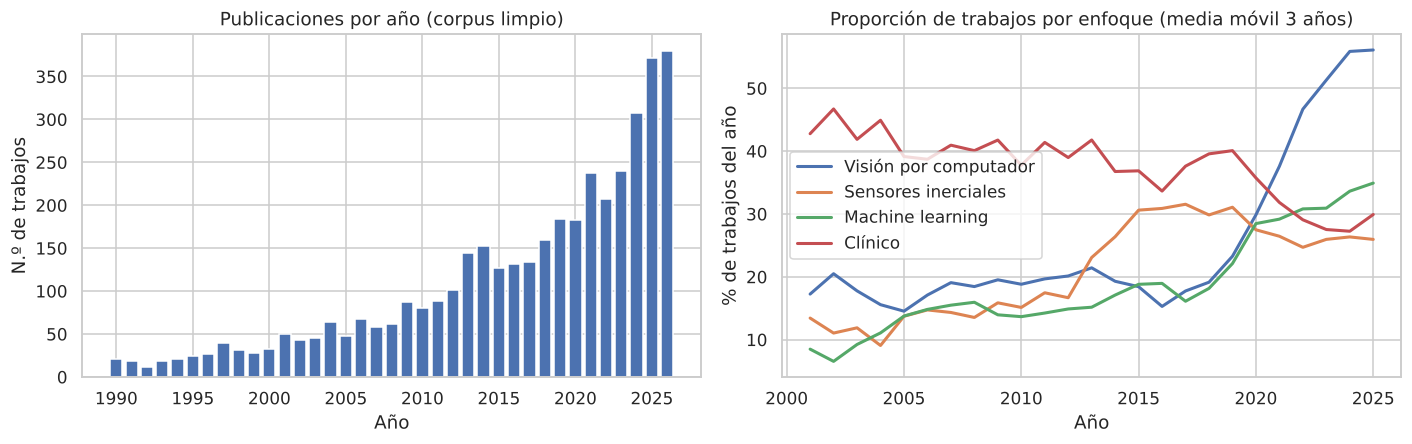

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
anual = df.groupby("anio").size()
axes[0].bar(anual.index, anual.values, color="#4C72B0")
axes[0].set(title="Publicaciones por año (corpus limpio)", xlabel="Año", ylabel="N.º de trabajos")
temas_anio = df[df["anio"] >= 2000].groupby("anio")[[f"tema_{t}" for t in TEMAS]].mean() * 100
temas_anio.columns = ["Visión por computador", "Sensores inerciales", "Machine learning", "Clínico"]
temas_anio.rolling(3, center=True).mean().plot(ax=axes[1], lw=2)
axes[1].set(title="Proporción de trabajos por enfoque (media móvil 3 años)", xlabel="Año", ylabel="% de trabajos del año")
plt.tight_layout(); plt.savefig(FIG / "art_tendencia_anual.png"); plt.show()

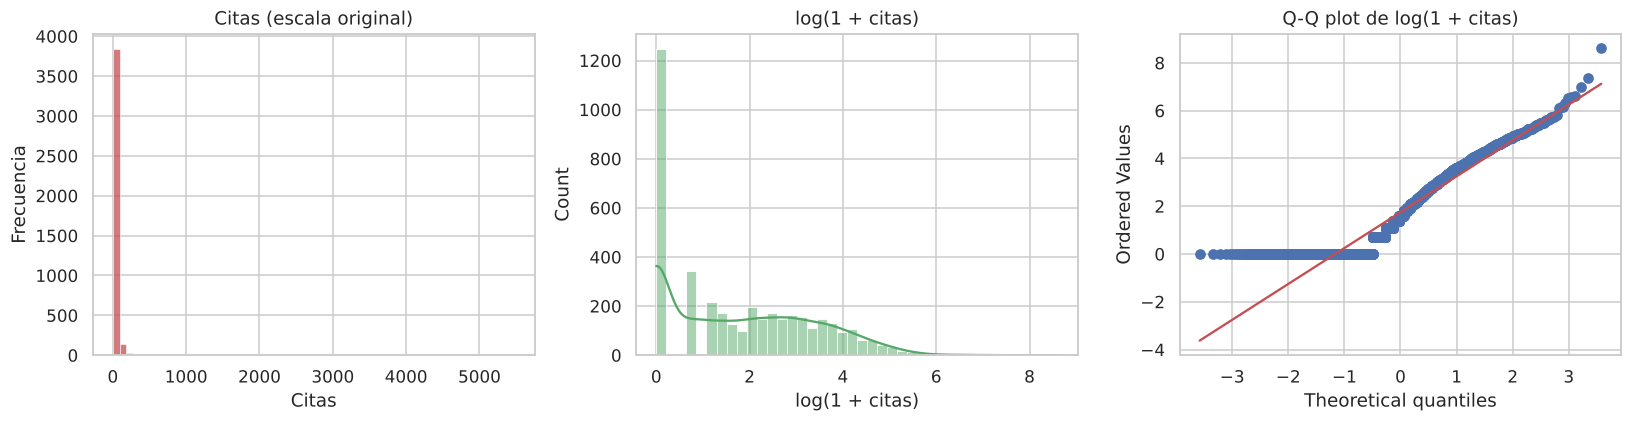

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["citas"], bins=60, ax=axes[0], color="#C44E52")
axes[0].set(title="Citas (escala original)", xlabel="Citas", ylabel="Frecuencia")
sns.histplot(df["log_citas"], bins=40, kde=True, ax=axes[1], color="#55A868")
axes[1].set(title="log(1 + citas)", xlabel="log(1 + citas)")
stats.probplot(df["log_citas"], dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot de log(1 + citas)")
plt.tight_layout(); plt.savefig(FIG / "art_distribucion_citas.png"); plt.show()

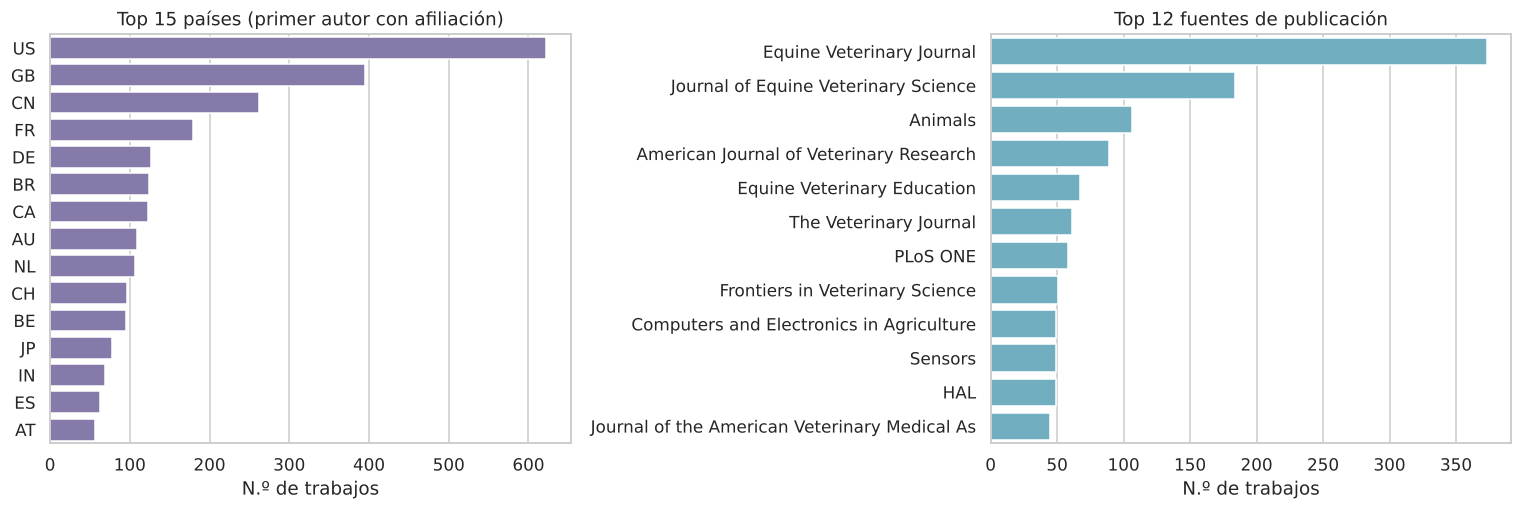

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
paises = df.loc[df["pais_principal"] != "Desconocido", "pais_principal"].value_counts().head(15)
sns.barplot(x=paises.values, y=paises.index, ax=axes[0], color="#8172B2")
axes[0].set(title="Top 15 países (primer autor con afiliación)", xlabel="N.º de trabajos", ylabel="")
rev = df.loc[df["revista"] != "Sin fuente registrada", "revista"].value_counts().head(12)
sns.barplot(x=rev.values, y=[r[:45] for r in rev.index], ax=axes[1], color="#64B5CD")
axes[1].set(title="Top 12 fuentes de publicación", xlabel="N.º de trabajos", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "art_paises_revistas.png"); plt.show()

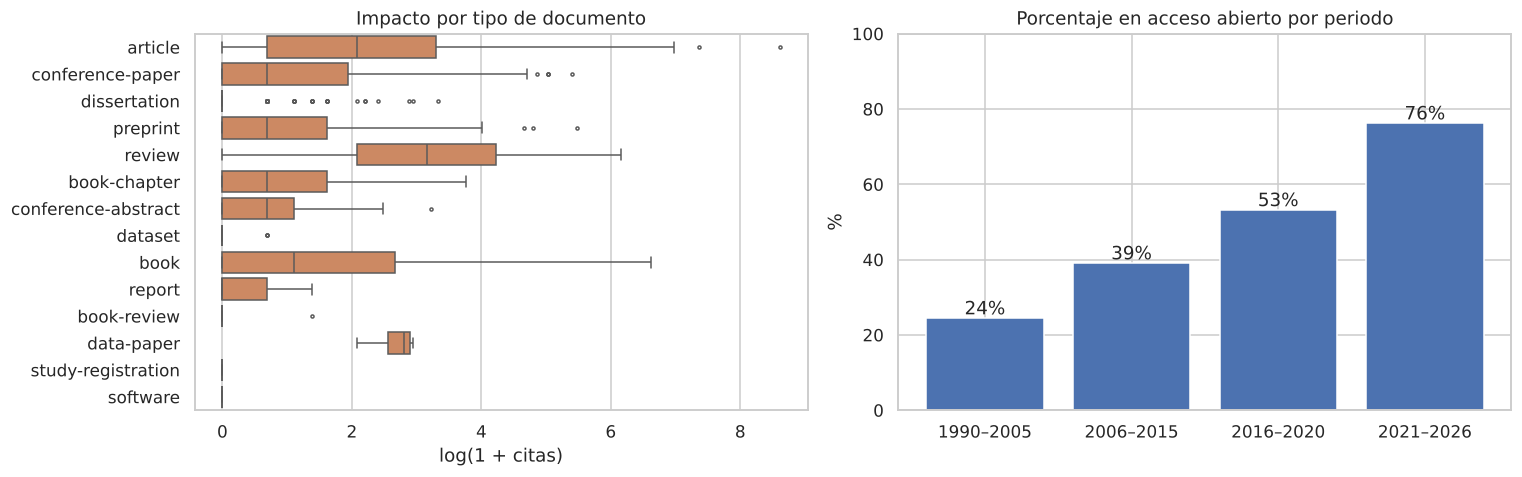

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
orden = df["tipo"].value_counts().index
sns.boxplot(data=df, x="log_citas", y="tipo", order=orden, ax=axes[0], color="#DD8452", fliersize=2)
axes[0].set(title="Impacto por tipo de documento", xlabel="log(1 + citas)", ylabel="")
oa = df.groupby("periodo")["acceso_abierto"].mean() * 100
axes[1].bar(oa.index.astype(str), oa.values, color="#4C72B0")
for i, v in enumerate(oa.values):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center")
axes[1].set(title="Porcentaje en acceso abierto por periodo", ylabel="%", ylim=(0, 100))
plt.tight_layout(); plt.savefig(FIG / "art_tipo_oa.png"); plt.show()

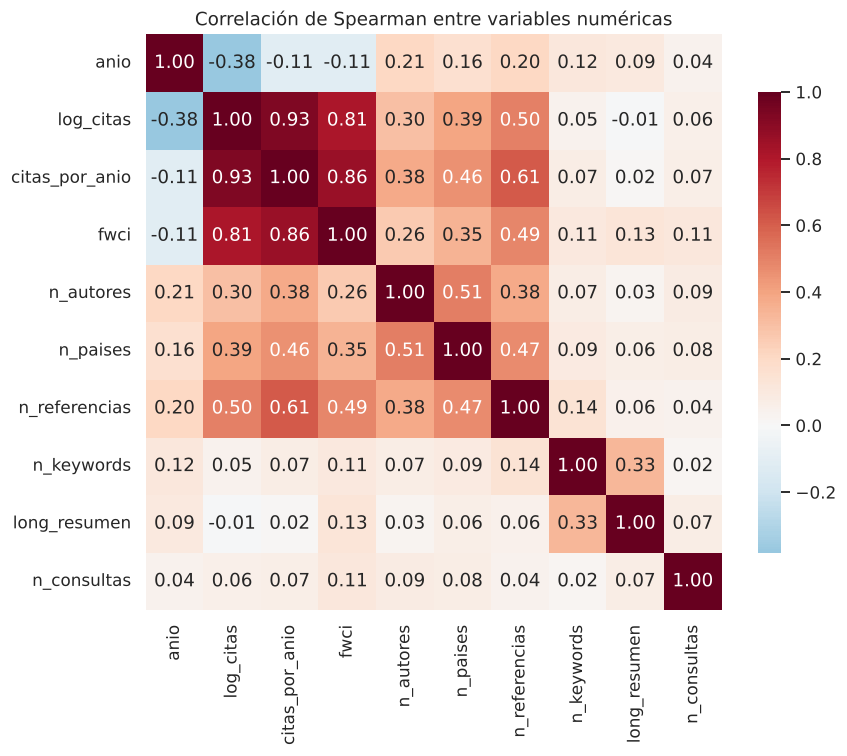

In [10]:
corr = df[["anio", "log_citas", "citas_por_anio", "fwci", "n_autores", "n_paises", "n_referencias", "n_keywords", "long_resumen", "n_consultas"]].corr(method="spearman")
plt.figure(figsize=(8.5, 6.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlación de Spearman entre variables numéricas")
plt.savefig(FIG / "art_correlaciones.png"); plt.show()

Se usa Spearman (por rangos) porque las variables no son normales y tienen valores extremos.

## 6. Detección e interpretación de outliers ("hacer hablar a los números")
Se combinan dos criterios sobre `citas_por_anio` (impacto ajustado por antigüedad):
- **IQR (Tukey)**: valor > Q3 + 1,5·IQR, calculado sobre `log(1+citas_por_anio)`.
- **z-score robusto (mediana/MAD)**: |z| > 3,5 (Iglewicz & Hoaglin), menos sensible a la propia cola.

Los outliers **no se eliminan**: en bibliometría, los trabajos atípicos son justamente los más influyentes
(métodos fundacionales, datasets de referencia). Se marcan y se interpretan.

In [11]:
x = np.log1p(df["citas_por_anio"])
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
df["outlier_iqr"] = x > q3 + 1.5 * iqr
mad = np.median(np.abs(x - x.median()))
df["z_robusto"] = 0.6745 * (x - x.median()) / mad
df["outlier_z"] = df["z_robusto"].abs() > 3.5
df["outlier"] = df["outlier_iqr"] | df["outlier_z"]
print(f"Outliers IQR: {df.outlier_iqr.sum()} | z robusto: {df.outlier_z.sum()} | unión: {df.outlier.sum()}")

top_out = df[df["outlier"]].sort_values("citas_por_anio", ascending=False)
top_out[["titulo", "anio", "citas", "citas_por_anio", "consulta", "tipo"]].head(15)

Outliers IQR: 59 | z robusto: 87 | unión: 87


,titulo,anio,citas,citas_por_anio,consulta,tipo
3440,DeepLabCut: markerless pose estimation of user...,2018.0,5478,608.666667,vision_pose_animal,article
4144,SLEAP: A deep learning system for multi-animal...,2022.0,1073,214.600000,vision_pose_animal,article
3439,Using DeepLabCut for 3D markerless pose estima...,2019.0,1581,197.625000,vision_pose_animal,article
3443,"Multi-animal pose estimation, identification a...",2022.0,723,144.600000,vision_pose_animal,article
3820,Keypoint-MoSeq: parsing behavior by linking po...,2024.0,311,103.666667,vision_pose_animal,article
3449,Fast animal pose estimation using deep neural ...,2018.0,691,76.777778,vision_pose_animal,article
3458,"DeepPoseKit, a software toolkit for fast and r...",2019.0,557,69.625000,vision_pose_animal,article
4167,Deep learning tools for the measurement of ani...,2019.0,472,59.000000,vision_pose_animal,review
3438,Anipose: A toolkit for robust markerless 3D po...,2021.0,342,57.000000,vision_pose_animal,article
3507,ViTPose++: Vision Transformer for Generic Body...,2023.0,217,54.250000,vision_pose_animal,article


In [12]:
comp = df.groupby("outlier")[[f"tema_{t}" for t in TEMAS] + ["acceso_abierto", "n_autores", "n_paises", "n_consultas"]].mean().T
comp.columns = ["Normal", "Outlier"]
comp["razon_outlier/normal"] = comp["Outlier"] / comp["Normal"]
comp.round(2)

,Normal,Outlier,razon_outlier/normal
tema_vision,0.32,0.82,2.53
tema_sensores,0.24,0.16,0.68
tema_ml,0.23,0.52,2.25
tema_clinico,0.36,0.10,0.28
acceso_abierto,0.55,0.89,1.60
n_autores,4.10,8.34,2.03
n_paises,0.97,1.80,1.85
n_consultas,1.13,1.11,0.99


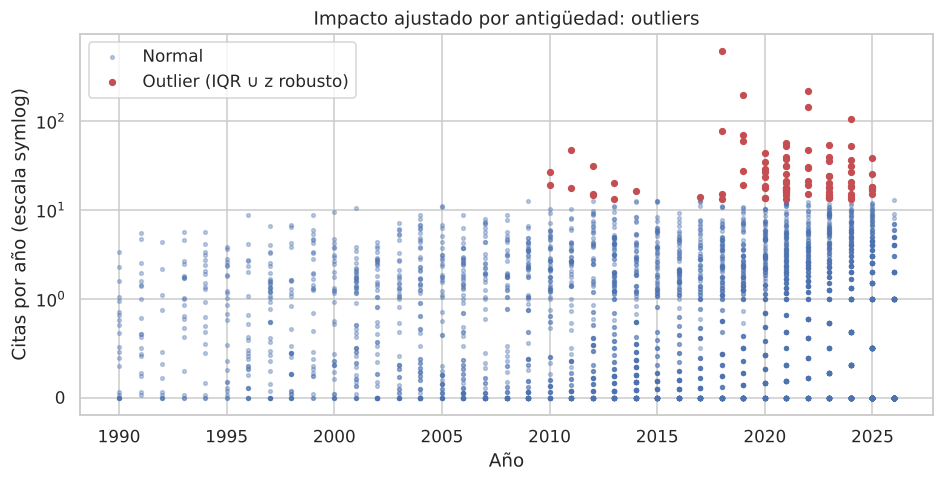

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(df.loc[~df.outlier, "anio"], df.loc[~df.outlier, "citas_por_anio"], s=6, alpha=.35, label="Normal")
ax.scatter(df.loc[df.outlier, "anio"], df.loc[df.outlier, "citas_por_anio"], s=14, c="#C44E52", label="Outlier (IQR ∪ z robusto)")
ax.set_yscale("symlog", linthresh=1)
ax.set(title="Impacto ajustado por antigüedad: outliers", xlabel="Año", ylabel="Citas por año (escala symlog)")
ax.legend()
plt.savefig(FIG / "art_outliers.png"); plt.show()

## 7. Exportación del dataset limpio

In [14]:
cols = ["openalex_id", "doi", "titulo", "anio", "periodo", "tipo", "idioma", "citas", "log_citas", "citas_por_anio", "fwci",
        "acceso_abierto", "revista", "n_autores", "paises", "pais_principal", "n_paises", "n_referencias", "keywords",
        "n_keywords", "conceptos", "topico", "subcampo", "campo", "tiene_resumen", "long_resumen", "texto", "consulta",
        "n_consultas"] + [f"tema_{t}" for t in TEMAS] + ["z_robusto", "outlier_iqr", "outlier_z", "outlier"]
df[cols].to_csv(OUT / "articulos_limpio.csv", index=False)
print("Guardado:", OUT / "articulos_limpio.csv", df[cols].shape)

Guardado: /home/claude/proyecto/data/processed/articulos_limpio.csv (4024, 37)
